# BioGPT Discharge Summary -- Colab Runner

Runs the full pipeline end to end on a Colab T4 GPU: data prep -> zero-shot baseline demo -> LoRA fine-tuning -> generation -> evaluation.

**Before you start:**
- If you have credentialed access to **MIMIC-IV-Ext-BHC** on PhysioNet, download it yourself (this notebook never does so automatically -- that would violate the Data Use Agreement) and upload the CSV to `data/raw/` in a later cell, then set `dataset.mode: mimic_bhc` in `config.yaml`.
- Otherwise, leave `config.yaml` on `dataset.mode: mtsamples`, the public fallback -- no credentialed access needed.
- Runtime > Change runtime type > GPU (T4) before running.

Each step below is also an ordinary script in `src/` -- this notebook is just an orchestrator, so you can always re-run an individual step from a terminal instead.

In [1]:
!nvidia-smi

Mon Oct  5 17:41:18 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Get the repo onto this runtime

Two options -- set `REPO_URL` below if your code is on GitHub, or leave it blank to upload a zip of the local project folder instead.

In [2]:
import os

REPO_URL = ""  # e.g. "https://github.com/<you>/biogpt-discharge-summary.git" -- leave blank to upload instead
REPO_DIR = "/content/biogpt-discharge-summary"

if REPO_URL:
    if not os.path.isdir(REPO_DIR):
        !git clone {REPO_URL} {REPO_DIR}
else:
    if not os.path.isdir(REPO_DIR):
        from google.colab import files
        print("Upload a zip of the biogpt-discharge-summary project folder (e.g. right-click the folder locally, ")
        print("Compress / Zip, then upload the .zip here).")
        uploaded = files.upload()
        zip_name = next(iter(uploaded))
        import zipfile
        with zipfile.ZipFile(zip_name) as zf:
            zf.extractall("/content/")
        # Handles the common case where the zip contains a single top-level folder.
        extracted = [d for d in os.listdir("/content") if "biogpt-discharge-summary" in d and os.path.isdir(f"/content/{d}")]
        if extracted and extracted[0] != "biogpt-discharge-summary":
            os.rename(f"/content/{extracted[0]}", REPO_DIR)

%cd {REPO_DIR}
!pip install -q -r requirements.txt

Upload a zip of the biogpt-discharge-summary project folder (e.g. right-click the folder locally, 
Compress / Zip, then upload the .zip here).


Saving biogpt-discharge-summary-colab.zip to biogpt-discharge-summary-colab.zip
/content/biogpt-discharge-summary
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 90.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.3/527.3 kB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.7/320.7 kB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 330.9/330.9 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.5/897.5 kB 62.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 99.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/

## Mount Google Drive for checkpoint persistence

Colab's free-tier T4 sessions can disconnect or time out, and `checkpoints/` is **not** committed to git (see `.gitignore`). Symlinking `checkpoints/` to a Drive folder means a dropped session doesn't cost you a from-scratch retrain -- `train.py` keeps writing to the same relative `checkpoints/` path, which now transparently points at Drive.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_CKPT_DIR = "/content/drive/MyDrive/biogpt-discharge-summary-checkpoints"
!mkdir -p {DRIVE_CKPT_DIR}
!rm -rf {REPO_DIR}/checkpoints
!ln -sfn {DRIVE_CKPT_DIR} {REPO_DIR}/checkpoints
print("checkpoints/ now points at Drive:", os.path.realpath(f"{REPO_DIR}/checkpoints"))

Mounted at /content/drive
checkpoints/ now points at Drive: /content/drive/MyDrive/biogpt-discharge-summary-checkpoints


## (Optional) Upload MIMIC-IV-Ext-BHC

Skip this cell entirely if you're using the `mtsamples` fallback (the default in `config.yaml`). If you have your own PhysioNet-downloaded MIMIC-IV-Ext-BHC CSV, upload it here and make sure `dataset.mode: mimic_bhc` is set in `config.yaml` (and that `dataset.mimic_bhc.input_column` / `target_column` match your export's actual column names).

In [4]:
UPLOAD_MIMIC = False  # flip to True to run this cell's upload

if UPLOAD_MIMIC:
    from google.colab import files
    os.makedirs("data/raw", exist_ok=True)
    uploaded = files.upload()
    for fname in uploaded:
        os.rename(fname, f"data/raw/{fname}")
    print("Uploaded to data/raw/. Update config.yaml's dataset.mimic_bhc.raw_path if the filename differs.")

## Step 1: Data prep

Loads whichever dataset `config.yaml` points at, cleans text, builds (input, target) pairs, splits 80/10/10 with a fixed seed, and reports token-length stats (using BioGPT's own tokenizer) including how many examples get truncated against the 768/256 token limits. See `src/data_prep.py` for the full reasoning, especially around why the MTSamples section-split is a heuristic that *drops* rows it can't confidently parse rather than guessing.

In [5]:
!python src/data_prep.py

17:42:56 [data_prep] INFO: Dataset mode: mtsamples
17:42:56 [data_prep] INFO: Local MTSamples CSV not found at /content/biogpt-discharge-summary/data/raw/mtsamples.csv; trying Hugging Face Hub mirror 'harishnair04/mtsamples'
Generating train split: 100% 4999/4999 [00:00<00:00, 13538.32 examples/s]
17:42:59 [data_prep] INFO: keep_specialties is null: using all specialties (regex split does the filtering).
17:43:01 [data_prep] INFO: MTSamples section split: 209 succeeded, 4757 dropped (no hospital-course-like section found)
17:43:01 [data_prep] INFO: Removed 108 duplicate notes (same note filed under multiple specialties)
17:43:01 [data_prep] INFO: Loaded 101 (input, target) pairs before tokenization/splitting.
config.json: 100% 595/595 [00:00<00:00, 5.74MB/s]
vocab.json: 927kB [00:00, 46.8MB/s]
merges.txt: 696kB [00:00, 94.8MB/s]
17:43:04 [data_prep] INFO:   train: 80 examples
17:43:04 [data_prep] INFO:   val: 10 examples
17:43:04 [data_prep] INFO:   test: 11 examples
17:43:04 [data_pre

{
  "dataset_mode": "mtsamples",
  "max_input_tokens": 768,
  "max_target_tokens": 256,
  "train": {
    "n_samples": 80,
    "avg_input_tokens": 399.1875,
    "avg_target_tokens": 239.75,
    "max_input_tokens_seen": 1229,
    "max_target_tokens_seen": 822,
    "n_input_truncated": 7,
    "pct_input_truncated": 8.75,
    "n_target_truncated": 28,
    "pct_target_truncated": 35.0
  },
  "val": {
    "n_samples": 10,
    "avg_input_tokens": 262.3,
    "avg_target_tokens": 211.8,
    "max_input_tokens_seen": 527,
    "max_target_tokens_seen": 546,
    "n_input_truncated": 0,
    "pct_input_truncated": 0.0,
    "n_target_truncated": 3,
    "pct_target_truncated": 30.0
  },
  "test": {
    "n_samples": 11,
    "avg_input_tokens": 396.45454545454544,
    "avg_target_tokens": 251.27272727272728,
    "max_input_tokens_seen": 854,
    "max_target_tokens_seen": 594,
    "n_input_truncated": 2,
    "pct_input_truncated": 18.18,
    "n_target_truncated": 5,
    "pct_target_truncated": 45.45
  }
}

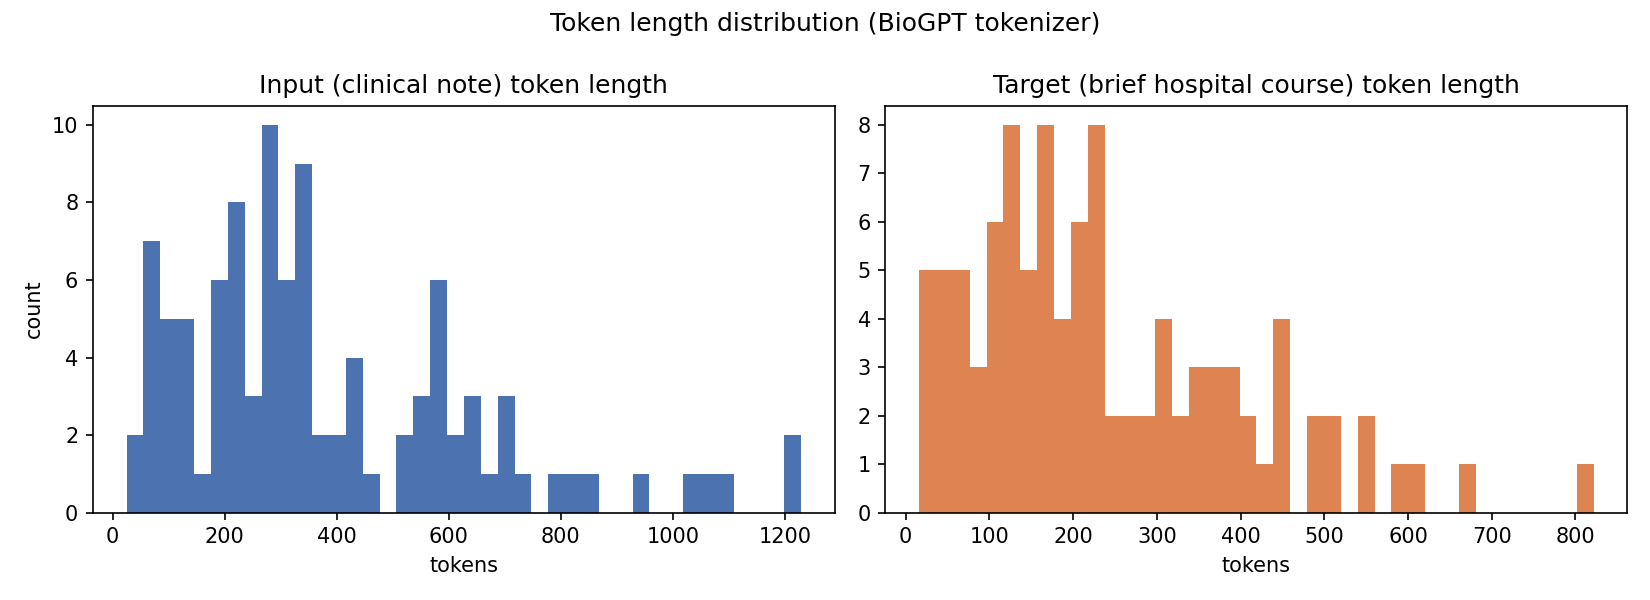

In [6]:
import json
from IPython.display import Image, display

print(json.dumps(json.load(open("outputs/dataset_stats.json")), indent=2))
display(Image("outputs/figures/token_length_histogram.png"))

## Step 2: Zero-shot baseline demo

Runs the base (not fine-tuned) BioGPT on three synthetic clinical prompts with greedy vs. sampling decoding, to make concrete the determinism-vs-variance point before any fine-tuning happens. No dataset or GPU training required for this step -- it's also a good smoke test that the environment and base model load correctly.

In [7]:
!python src/baseline_demo.py

I0000 00:00:1791222197.209705    2434 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791222199.526788    2434 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
17:43:22 [baseline_demo] INFO: Device: cuda
17:43:22 [baseline_demo] INFO: Loading base model microsoft/biogpt ...
pytorch_model.bin: 100% 1.56G/1.56G [00:14<00:00, 108MB/s]
17:43:39 [baseline_demo] INFO: Prompt 1/3: 'Patient presented with shortness of breath and elevated blood pressure. Diagnosis: '
17:43:41 [baseline_demo] INFO: Prompt 2/3: 'A 65-year-old male admitted with chest pain radiating to the left arm. Hospital course: '
17:43:42 [baseline_demo] INFO: Prompt 3/3: 'Patient with type 2 diabetes admitted for diabetic ketoacidosis. Treatment included '
You se

In [8]:
from IPython.display import Markdown, display
display(Markdown(open("outputs/baseline_demo.md").read()))

# Baseline Demo: Zero-Shot BioGPT, Greedy vs. Sampling

Base model: `microsoft/biogpt` (no fine-tuning). Prompts are synthetic/templated -- no real patient data.

**Point being demonstrated:** greedy decoding (`do_sample=False`) is deterministic -- rerunning it produces the exact same text every time. Sampling (`do_sample=True, top_k=50, top_p=0.95`) is stochastic -- three runs with three different seeds below produce three different continuations from the identical prompt. For a system generating clinical text, that variance is a real design consideration: reproducibility vs. diversity of phrasing.

## Prompt 1
> Patient presented with shortness of breath and elevated blood pressure. Diagnosis: 

**Greedy (do_sample=False), run twice to confirm determinism:**

```
Patient presented with shortness of breath and elevated blood pressure. Diagnosis:  a case report.
```
*Identical on rerun: True*

**Sampling (do_sample=True, top_k=50, top_p=0.95), 3 runs with different seeds:**

*seed=0:*
```
Patient presented with shortness of breath and elevated blood pressure. Diagnosis:  giant cell arteritis.
```
*seed=1:*
```
Patient presented with shortness of breath and elevated blood pressure. Diagnosis:  pheochromocytoma.
```
*seed=2:*
```
Patient presented with shortness of breath and elevated blood pressure. Diagnosis:  Primary Adrenal Insufficiency.
```
*All 3 sampling runs identical: False (expected: False)*

## Prompt 2
> A 65-year-old male admitted with chest pain radiating to the left arm. Hospital course: 

**Greedy (do_sample=False), run twice to confirm determinism:**

```
A 65-year-old male admitted with chest pain radiating to the left arm. Hospital course:  acute myocardial infarction (AMI).
```
*Identical on rerun: True*

**Sampling (do_sample=True, top_k=50, top_p=0.95), 3 runs with different seeds:**

*seed=0:*
```
A 65-year-old male admitted with chest pain radiating to the left arm. Hospital course:  pain relief was brief.
```
*seed=1:*
```
A 65-year-old male admitted with chest pain radiating to the left arm. Hospital course:  ECG showed ST segment elevation in leads II, III and aVF, and cardiac enzyme levels were elevated, although the levels of troponin-I and creatine kinase-MB were normal.
```
*seed=2:*
```
A 65-year-old male admitted with chest pain radiating to the left arm. Hospital course:  he was normotensive and nonsmoker.
```
*All 3 sampling runs identical: False (expected: False)*

## Prompt 3
> Patient with type 2 diabetes admitted for diabetic ketoacidosis. Treatment included 

**Greedy (do_sample=False), run twice to confirm determinism:**

```
Patient with type 2 diabetes admitted for diabetic ketoacidosis. Treatment included  insulin therapy, fluid therapy, and bicarbonate infusion.
```
*Identical on rerun: True*

**Sampling (do_sample=True, top_k=50, top_p=0.95), 3 runs with different seeds:**

*seed=0:*
```
Patient with type 2 diabetes admitted for diabetic ketoacidosis. Treatment included  strict metabolic control, intensive insulin therapy (target blood glucose levels 80-110 mg / dl), and fluids were given to maintain urine output.
```
*seed=1:*
```
Patient with type 2 diabetes admitted for diabetic ketoacidosis. Treatment included  intravenous fluids and bicarbonate.
```
*seed=2:*
```
Patient with type 2 diabetes admitted for diabetic ketoacidosis. Treatment included  intravenous fluids and insulin.
```
*All 3 sampling runs identical: False (expected: False)*


## Step 3: LoRA fine-tuning

Fine-tunes BioGPT with LoRA adapters on the attention projections (`q_proj`, `k_proj`, `v_proj`, `out_proj` -- confirmed against BioGPT's source, printed again at the start of this run as a runtime sanity check). The loss is masked to the target (Brief Hospital Course) tokens only, so the model learns to *summarize*, not to reproduce the input note. Expect this to take a while on a T4 -- `config.yaml`'s `training` section controls batch size / epochs / etc. if you need to shorten it for a quick test.

In [9]:
!python src/train.py

I0000 00:00:1791222230.826812    2643 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791222233.191285    2643 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
17:43:57 [train] INFO: Device: cuda
Generating train split: 80 examples [00:00, 16349.67 examples/s]
Generating validation split: 10 examples [00:00, 6845.61 examples/s]
Tokenizing + masking prompt tokens: 100% 80/80 [00:01<00:00, 56.11 examples/s]
Tokenizing + masking prompt tokens: 100% 10/10 [00:00<00:00, 80.69 examples/s]
17:44:01 [train] INFO: Loading base model microsoft/biogpt ...
17:44:01 [train] INFO: nn.Linear submodule names found in model: ['fc1', 'fc2', 'k_proj', 'out_proj', 'output_projection', 'q_proj', 'v_proj']
trainable params: 3,145,728 || all para

{
  "base_model": "microsoft/biogpt",
  "lora_config": {
    "r": 16,
    "alpha": 32,
    "dropout": 0.05,
    "target_modules": [
      "q_proj",
      "k_proj",
      "v_proj",
      "out_proj"
    ],
    "bias": "none",
    "task_type": "CAUSAL_LM"
  },
  "training_config": {
    "per_device_train_batch_size": 4,
    "per_device_eval_batch_size": 4,
    "gradient_accumulation_steps": 2,
    "learning_rate": 0.0002,
    "num_train_epochs": 20,
    "early_stopping_patience": 3,
    "fp16": true,
    "gradient_checkpointing": true,
    "eval_strategy": "epoch",
    "save_strategy": "epoch",
    "load_best_model_at_end": true,
    "metric_for_best_model": "eval_loss",
    "greater_is_better": false,
    "logging_steps": 1,
    "warmup_ratio": 0.03,
    "weight_decay": 0.01,
    "save_total_limit": 2
  },
  "param_counts": {
    "trainable_params": 3145728,
    "total_params": 349908992,
    "trainable_pct": 0.899
  },
  "final_train_loss": 2.889437380203834,
  "best_eval_loss": 2.92139

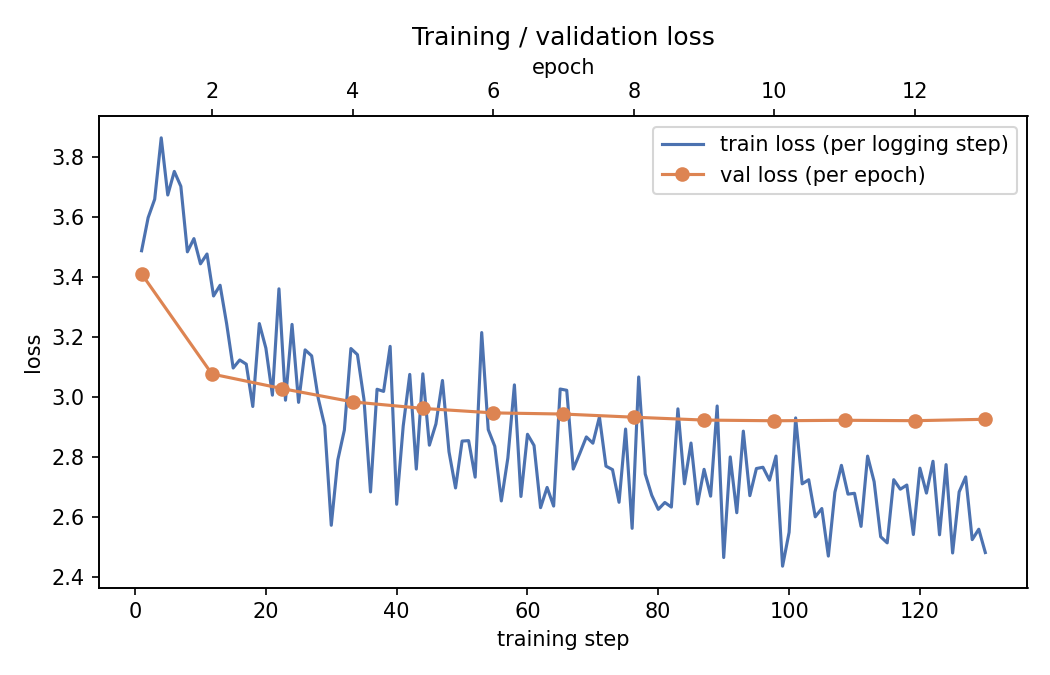

In [10]:
print(json.dumps(json.load(open("outputs/train_summary.json")), indent=2))
display(Image("outputs/figures/loss_curve.png"))

## Step 4: Generation on the test set

Generates summaries for every test example with the base model (zero-shot, greedy) and the fine-tuned model (greedy and sampling), reusing a single loaded model via `disable_adapter()` to keep GPU memory down. If this is taking too long on the free tier, lower `generation.max_test_examples` in `config.yaml` to a smaller number and re-run.

In [11]:
!python src/generate.py

I0000 00:00:1791222468.306016    3726 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791222471.382594    3726 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
17:47:54 [generate] INFO: Device: cuda
17:47:55 [generate] INFO: Generating for 11 test examples.
17:47:55 [generate] INFO: Loading base model microsoft/biogpt ...
Generating: 100% 11/11 [01:37<00:00,  8.85s/it]
17:49:33 [generate] INFO: Saved /content/biogpt-discharge-summary/outputs/test_generations.csv (11 rows)


In [12]:
import pandas as pd
pd.read_csv("outputs/test_generations.csv").head(3)

,id,input,reference,base_greedy,ft_greedy,ft_sampling
0,mts_3852,"ADMISSION DIAGNOSES:,1. Syncope.\n2. End-stage...",The patient is a 44-year-old African-American ...,", 1-2 days. (1-2). (1). (2)., 2-3 days. (2-3)....",The patient was admitted to the hospital for e...,The patient was admitted for HD 5 days ago and...
1,mts_3541,"CHIEF COMPLAINT:, Stomach pain for 2 weeks.\nH...",The patient was admitted to the hospital for f...,"., 1-2 days., 1 day., 1 wk., 1 mo., 1 yr., 2 m...",The patient was admitted to the hospital for f...,Intravenous Cimetidine. The patient initially ...
2,mts_137,"ADMITTING DIAGNOSES:,1. Hematuria.\n2. Benign ...",This is a 77-year-old African-American male wh...,", 1-2. & # # # # Notice:: www.clinicaltrials.g...",The patient was admitted to the hospital for e...,The patient was admitted for observation and o...


## Step 5: Evaluation

ROUGE-1/2/L, BERTScore, the approximate hallucination proxy (explicitly *not* a validated factuality metric -- see `src/evaluate.py`'s docstring), and a sampling-reproducibility check (mean pairwise ROUGE-L between repeated sampling runs on the same prompt vs. repeated greedy runs). This is the step that produces the headline numbers for the model card.

In [13]:
!python src/evaluate.py

I0000 00:00:1791222581.151585    4232 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791222583.779731    4232 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
17:49:46 [evaluate] INFO: Loaded 11 test generations.
17:49:47 [evaluate] INFO: ROUGE base_greedy={'rouge1': 0.0376, 'rouge2': 0.0065, 'rougeL': 0.0257} ft_greedy={'rouge1': 0.273, 'rouge2': 0.0782, 'rougeL': 0.1745}
config.json: 100% 385/385 [00:00<00:00, 3.11MB/s]
vocab.txt: 213kB [00:00, 24.0MB/s]
pytorch_model.bin: 100% 436M/436M [00:02<00:00, 192MB/s]
17:49:55 [evaluate] INFO: BERTScore base={'precision': 0.5427, 'recall': 0.5125, 'f1': 0.5256, 'model_used': 'emilyalsentzer/Bio_ClinicalBERT'} ft={'precision': 0.6846, 'recall': 0.6505, 'f1': 0.6632, 'model_used':

{
  "dataset_mode": "mtsamples",
  "n_test_examples": 11,
  "rouge": {
    "base_greedy": {
      "rouge1": 0.0376,
      "rouge2": 0.0065,
      "rougeL": 0.0257
    },
    "ft_greedy": {
      "rouge1": 0.273,
      "rouge2": 0.0782,
      "rougeL": 0.1745
    },
    "ft_sampling": {
      "rouge1": 0.2247,
      "rouge2": 0.042,
      "rougeL": 0.1327
    }
  },
  "bertscore": {
    "base_greedy": {
      "precision": 0.5427,
      "recall": 0.5125,
      "f1": 0.5256,
      "model_used": "emilyalsentzer/Bio_ClinicalBERT"
    },
    "ft_greedy": {
      "precision": 0.6846,
      "recall": 0.6505,
      "f1": 0.6632,
      "model_used": "emilyalsentzer/Bio_ClinicalBERT"
    }
  },
  "hallucination_proxy": {
    "description": "Approximate lexical proxy: % of extracted medical-looking terms (capitalized words, drug-name suffixes, numbers+units) from the generated text that do not appear verbatim in the source note. NOT a validated hallucination/factuality metric -- see README for lim

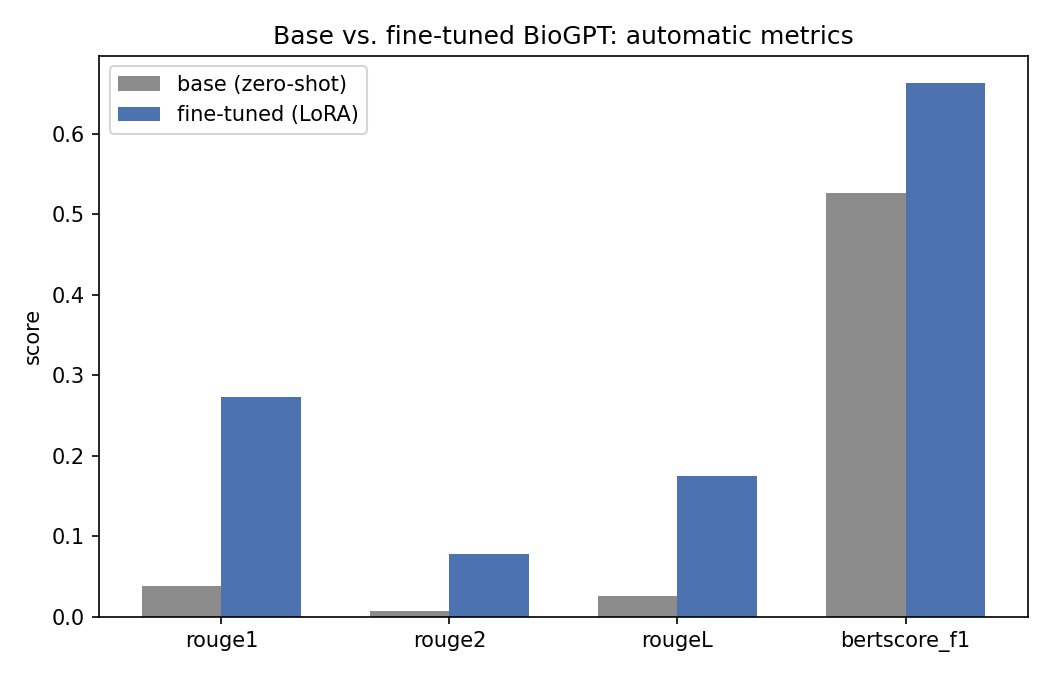

In [14]:
print(json.dumps(json.load(open("outputs/metrics.json")), indent=2))
display(Image("outputs/figures/metrics_comparison.png"))

In [15]:
display(Markdown(open("outputs/qualitative_examples.md").read()))

# Qualitative Examples

3 highest-ROUGE-L and 3 lowest-ROUGE-L fine-tuned (greedy) generations on the test set, by `ft_greedy` vs. `reference` ROUGE-L. Hallucination flags use the same approximate lexical proxy described in outputs/metrics.json -- NOT a validated clinical fact-checker.

# Good examples
## Good (id=mts_3541, ROUGE-L=0.238)

**Reference:**
```
The patient was admitted to the hospital for further evaluation. A diagnostic procedure was performed.
```
**Fine-tuned generation (greedy):**
```
The patient was admitted to the hospital for further evaluation. The patient was started on IV fluids and IV antibiotics. The patient's pain was relieved and his bowel movements were improved. The patient also had a nasogastric tube placed. The patient had a nasogastric tip placed and the nasogastric tube was removed. The patient did not have any episodes of vomiting or diarrhea. The patient continued to have abdominal pain and was started on oral antibiotics. The pain resolved and the patient was discharged home.
```

## Good (id=mts_2581, ROUGE-L=0.222)

**Reference:**
```
The patient was admitted on 09/04/2007 to undergo total vaginal hysterectomy. The procedure preceded as planned without complication. Uterus was sent for pathologic analysis. The patient was monitored in the hospital, 2 days postoperatively. She recovered quite well and vitals remained stable.
Laboratory studies, H&H were followed and appeared stable on 09/05/2007 with hemoglobin of 11.2 and hematocrit of 31.8.
The patient was ready for discharge on Monday morning of 09/06/2007.
```
**Fine-tuned generation (greedy):**
```
The patient was admitted to the hospital for further evaluation. The patient had an uncomplicated postoperative course. The patient's postoperative course was unremarkable. The patient returned to the office on the second postoperative day. The patient did not complain of any pain or discomfort. The patient is being followed up in the outpatient clinic.
```

## Good (id=mts_2614, ROUGE-L=0.220)

**Reference:**
```
The patient was admitted to the surgical suite and taken to the operating room where a dilatation and curettage (D&C) was performed. Hysteroscopy revealed a large endometrial cavity fibroid. Careful shaving and excision of this fibroid was performed with removal of the fibroid. Hemostasis was noted completely at the end of this procedure. Postoperatively, the patient has done well. The patient was given a 2nd unit of packed red blood cells because of intraoperative blood loss. The patient is now ambulating without difficulty and tolerating her diet. The patient desires to go home. The patient is discharged to home.
```
**Fine-tuned generation (greedy):**
```
The patient was admitted to the hospital for evaluation of menometrorhagia unresponsive for medical therapy. She was admitted to Dr. X p.R.n. and Dr. X-Ray. She was given a diagnostic hysteroscopy. The procedure was successful. The patient's hematocrit improved to 25, hemoglobin was 8.3. The patient returned to normal activity. The patient had no complications. The patient did not require any further transfusions. The patient tolerated the procedure well. She was discharged home. She was able to return to work. She was advised to return to her family. She was also advised to return for a follow-up visit. She was sent to Dr. X-ray. The patient showed no evidence of a uterine fibroid. The patient said that she would have a repeat hysteroscopy if she had a similar procedure.
```

# Bad examples
## Bad (id=mts_3387, ROUGE-L=0.130)

**Reference:**
```
The child was observed on IV fluids and advanced to clear liquids and then regular diet as tolerated. On the second hospital day, mother was comfortable taking her to home. Mother did not have a good explanation for the weight loss. In the hospital, her weight was 124 pounds, her height 58 inches, temperature 98.0 degree F., pulse 123, respirations 18, blood pressure 148/94. Follow up blood pressure were some of them were in the 125 to 70 range making us think her hypertension as labile and perhaps related to the excitement of the admission.
She seem quite happy and in no distress at the time of discharge. We will follow up in the office and try to further evaluate her for the unexplained weight loss. She has been taking the Adderall for at least a year, and the mother does not think the Adderall is the cause of the weight loss. The free T4 is borderline high and probably bears repeating along with further studies for Graves disease as an outpatient.
```
**Fine-tuned generation (greedy):**
```
The patient was admitted to the hospital and given MiraLax.She was started on oral clonidine and Adderall. She was started to take Adderall for her hyperactivity and constipation. She was also started on laxatives. She was given a bowel preparation and was started on a diet. She was then started on a low-residue diet. She had a good response to this. She was discharged home on a diet and laxative.
```
*No proxy-flagged terms.*

## Bad (id=mts_3852, ROUGE-L=0.120)

**Reference:**
```
The patient is a 44-year-old African-American male who was diagnosed with end-stage renal disease requiring hemodialysis three times per week approximately four to five months ago. He reports that over the past month, he has been feeling lightheaded when standing and has had three syncopal episodes during this time with return of consciousness after several minutes. He reportedly had this even while seated and denied overt dizziness. He reports this lightheadedness is made even worse when standing. He has had these symptoms almost daily over the past month. He does report some confusion when he awakens. He reports that he loses consciousness for two to three minutes. Denies any bowel or bladder loss, although he reports very little urine output secondary to his end-stage renal disease. He denied any palpitations, warmth, or diaphoresis, which is indicative of vasovagal syncope. There were no witnesses to his syncopal episodes. He also denied any clonic activity and no history of seizures. In the emergency room, the patient was given fluids and orthostatics were checked. At that time, orthostatics were negative; however, due to the fact that fluid had been given before, it is impossible to rule out orthostatic hypotension. The patient presented to the hospital on Coreg 12.5 mg b.i.d. and lisinopril 10 mg daily secondary to his hypertension, congestive heart failure with dilated cardiomyopathy and end-stage renal disease. Regarding his syncopal episodes, he was admitted with likely orthostatic hypotension. Cardiology was consulted and their recommendations were to reduce the lisinopril to 5 mg daily. At that time, the Coreg had been held secondary to hypotension. Cardiology also ordered a nuclear medicine myocardial perfusion stress test. Regarding the end-stage renal disease, Nephrology was consulted as the patient was due for hemodialysis treatment the day following admission. Nephrology was able to perform dialysis on the patient and Renal concurred that the presyncopal symptoms were likely due to decreased intravascular volume in the postdialytic time frame. Renal agreed with decreasing his lisinopril to 5 mg daily and decreasing the Coreg to 6.25 mg b.i.d. They reported that the Procrit should be continued. As previously indicated regarding the dilated cardiomyopathy, Cardiology ordered a nuclear medicine stress test to be performed. Also, regarding the patient's hypertension, he actually was noted to have hypotension on admission, and as previously stated, the Coreg was originally discontinued and then it was restarted at 6.25 mg b.i.d. and the patient tolerated this well. The patient's hospital course remained uncomplicated until September 17, 2007, the day the nuclear medicine stress test was scheduled. The patient stated that he was reluctant to proceed with the test and he was afraid of needles and the risks associated with the test although the procedure was explained to the patient and the risks of the procedure were quit low, the patient proceeded to discharge himself against medical advice.
```
**Fine-tuned generation (greedy):**
```
The patient was admitted to the hospital for evaluation of syncope. He was admitted to a telemetry unit. He was tachycardic and hypotensive. He was treated with IV fluids and IV nitroglycerin. He was started on IV fluids and nitroglycerin. He had a good response. He was transferred to the intensive care unit. He had an episode of syncope. His labs were unremarkable. He was placed on IV fluids, IV nitroglycerin, and IV fluids and oral nitroglycerin. His labs remained unremarkable. He had no episodes of syncope. The patient was transferred to a cardiology service.
```
*No proxy-flagged terms.*

## Bad (id=mts_1899, ROUGE-L=0.090)

**Reference:**
```
At the time of transfer to ABCD, these were the following issues.
```
**Fine-tuned generation (greedy):**
```
The baby was born at the ABCD Hospital on 07 / 12 / 2006. The mother was a 20-years-old gravidus 1, para 1, who received prenatal treatment for preeclampsia and was admitted to the hospital for evaluation of fetal distress. The mother had a history of hypertension and diabetes mellitus. The mother's condition was complicated by preeclampsia and was treated with magnesium sulfate. The baby was delivered at the ABCDC Hospital on 07 (12 / 15 / 2006).
```
**Terms in generation not found in source note (proxy flag, verify manually):**
`ABCDC`


In [17]:
!zip -r /content/outputs.zip outputs
!cp /content/outputs.zip /content/drive/MyDrive/biogpt-discharge-summary-checkpoints/
from google.colab import files
files.download("/content/outputs.zip")

updating: outputs/ (stored 0%)
updating: outputs/dataset_stats.json (deflated 74%)
updating: outputs/trainer_state.json (deflated 81%)
updating: outputs/metrics.json (deflated 63%)
updating: outputs/test_generations.csv (deflated 65%)
updating: outputs/figures/ (stored 0%)
updating: outputs/figures/loss_curve.png (deflated 6%)
updating: outputs/figures/token_length_histogram.png (deflated 20%)
updating: outputs/figures/metrics_comparison.png (deflated 22%)
updating: outputs/qualitative_examples.md (deflated 63%)
updating: outputs/baseline_demo.md (deflated 70%)
updating: outputs/train_summary.json (deflated 53%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
!rm -f /content/biogpt_results.zip
!zip -r -q /content/biogpt_results.zip outputs checkpoints/lora_adapter
!ls -lh /content/biogpt_results.zip
from google.colab import files
files.download("/content/biogpt_results.zip")

-rw-r--r-- 1 root root 12M Oct  5 17:56 /content/biogpt_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What you now have for the Model Card

All under `outputs/` (and persisted checkpoints under Drive via the symlink set up above):

- `dataset_stats.json`, `figures/token_length_histogram.png` -- Data section
- `baseline_demo.md` -- "Working Principle in Action" (greedy determinism vs. sampling variance)
- `train_summary.json` (incl. trainable/total param counts), `figures/loss_curve.png`, `trainer_state.json` -- Training Details
- `test_generations.csv` -- raw generations, all four columns, for spot-checking
- `metrics.json`, `figures/metrics_comparison.png` -- Quantitative Metrics + Reproducibility
- `qualitative_examples.md` -- Qualitative Analysis / Limitations (good + bad examples, hallucination-proxy flags)

Every number in these files came from an actual run of this notebook -- none of it is fabricated or hand-written, which is exactly what you want to be able to say in the model card's evaluation section.